# Notebook 10a — `10a_tpt_3dim`

## Overview

**Purpose:** Estimate the two-way fixed-effects association between flood exposure and the open-unemployment rate (`tpt_pct`, modelled on a log scale) using the three composite flood dimensions. This is the unemployment outcome the manuscript reports as *suggestive but fragile* under RQ2.

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` + `pre_transform` sheets) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

## Workflow

| Step | Description |
|---|---|
| 1 | Load the panel and define the flood predictors, controls, and outcome |
| 2 | Pre-estimation tests (missing values, VIF, panel balance, predictor correlation) |
| 3 | Estimator selection — CEM vs FE vs RE (Chow, LM, Hausman/Mundlak) |
| 4 | Significance — individual coefficient t-tests and the joint flood-block Wald test (log scale, confirmed on raw) |
| 5 | Clustered vs Driscoll–Kraay standard errors (Pesaran CD) |
| 6 | Model evaluation and robustness (residual diagnostics, AIC/BIC, control ladder) |
| 7 | Export the model fit for the social comparison notebook |

## Outputs

| File | Description |
|---|---|
| `fit_10a.json` | Model fit metrics (read by Notebook 10e, the social comparison) |

---
## STEP 1 — Load the panel and define the specification

Load the Notebook 8 panel, and define the three log flood dimensions, the two controls (log-population and mean years of schooling), the log-scale outcome `tpt_pct`, and the raw point-percent twin `tpt_pct_raw` for a scale-robustness check.

In [2]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Load the panel
# ═════════════════════════════════════════════════════════════
import numpy as np, pandas as pd
from linearmodels.panel import PanelOLS, RandomEffects, PooledOLS
from numpy.linalg import inv
from scipy.stats import chi2, jarque_bera
from scipy import stats as _st
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

PANEL_PATH = "../data/processed/8_panel_data.xlsx"
_t = pd.read_excel(PANEL_PATH, sheet_name="transformed")
_p = pd.read_excel(PANEL_PATH, sheet_name="pre_transform")
_id = ["bps_kab_code","year"]; _rc = [c for c in _p.columns if c not in _t.columns]
panel = _t.merge(_p[_id+_rc], on=_id, how="left").sort_values(["bps_kab_code","year"])

FLOOD = ["event_count_log", "HCI_log", "PDI_log"]
CONTROLS = ["log_population", "rls_years"]
X = FLOOD + CONTROLS
OUTCOME = "tpt_pct"          # log-scale headline (log1p applied in nb8)
OUTCOME_RAW = "tpt_pct_raw"  # raw point-% for robustness
pdat = panel.set_index(["bps_kab_code","year"])
print(f"Loaded {len(panel)} obs | outcome={OUTCOME} (log) | flood predictors: {len(FLOOD)}")
print(f"  raw robustness column present: {OUTCOME_RAW in panel.columns}")

Loaded 5140 obs | outcome=tpt_pct (log) | flood predictors: 3
  raw robustness column present: True


## STEP 2 — Pre-estimation tests

In [4]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Pre-estimation tests
# ═════════════════════════════════════════════════════════════
print("Missing values per model column:")
print(panel[[OUTCOME]+X].isna().sum().to_string()); print()
Xc = panel[X].dropna(); Xn = (Xc-Xc.mean())/(Xc.std()+1e-12)
vif = pd.Series(np.diag(inv(np.corrcoef(Xn, rowvar=False))), index=X)
print("VIF (multicollinearity):"); print(vif.round(2).to_string())
print(f"  max VIF = {vif.max():.2f} ({'OK <5' if vif.max()<5 else 'CAUTION >5'})\n")
bc = panel.groupby("bps_kab_code")["year"].count()
print(f"Panel balance: {bc.min()}-{bc.max()} yrs/regency "
      f"({'balanced' if bc.nunique()==1 else 'unbalanced'}), N={panel.bps_kab_code.nunique()}")

Missing values per model column:
tpt_pct            0
event_count_log    0
HCI_log            0
PDI_log            0
log_population     0
rls_years          0

VIF (multicollinearity):
event_count_log    3.18
HCI_log            1.21
PDI_log            3.31
log_population     1.19
rls_years          1.01
  max VIF = 3.31 (OK <5)

Panel balance: 10-10 yrs/regency (balanced), N=514


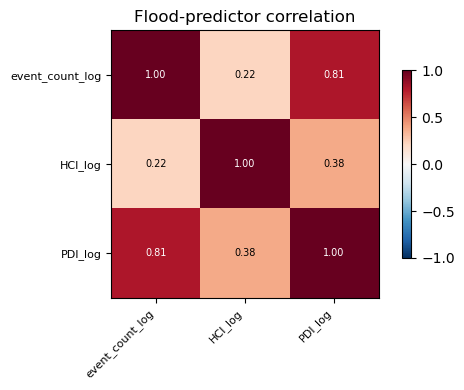

In [5]:
cc = panel[FLOOD].corr()
fig, ax = plt.subplots(figsize=(1.2*len(FLOOD)+2, 1.0*len(FLOOD)+1))
im = ax.imshow(cc.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FLOOD))); ax.set_xticklabels(FLOOD, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(FLOOD))); ax.set_yticklabels(FLOOD, fontsize=8)
for i in range(len(FLOOD)):
    for j in range(len(FLOOD)):
        ax.text(j,i,f"{cc.values[i,j]:.2f}",ha="center",va="center",fontsize=7,
                color="white" if abs(cc.values[i,j])>0.5 else "black")
plt.colorbar(im, shrink=0.7); ax.set_title("Flood-predictor correlation"); plt.tight_layout(); plt.show()

## STEP 3 — Estimator selection — CEM vs FE vs RE (Chow · LM · Hausman)

In [10]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Estimator selection — CEM vs FE vs RE
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
cem = PooledOLS(sub[OUTCOME], sub[X].assign(const=1)).fit()
fe  = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True,
               drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
re  = RandomEffects(sub[OUTCOME], sub[X].assign(const=1)).fit()
print("ESTIMATORS")
print(f"  CEM R2={cem.rsquared:.4f} | FE within-R2={fe.rsquared_within:.4f} | RE R2={re.rsquared:.4f}")
print(f"\n[Chow] F entity effects: F={fe.f_pooled.stat:.2f}, p={fe.f_pooled.pval:.4g} -> "
      + ("FE over CEM" if fe.f_pooled.pval<0.05 else "CEM ok"))
_u=pd.DataFrame({"u":cem.resids.values}, index=cem.resids.index)
_g=_u.groupby(level=0)["u"]; _T=_g.count(); _n=len(_u)
if _T.nunique()==1:
    LM=(_n/(2*(_T.iloc[0]-1)))*((_g.sum()**2).sum()/(_u["u"]**2).sum()-1)**2
    print(f"[LM] Breusch-Pagan: LM={LM:.2f}, p={1-chi2.cdf(LM,1):.4g} -> "
          + ("individual effects" if (1-chi2.cdf(LM,1))<0.05 else "none"))
common=[c for c in FLOOD if c in fe.params.index and c in re.params.index]
d=(fe.params[common]-re.params[common]).values
vd=(fe.cov.loc[common,common]-re.cov.loc[common,common]).values
h=float(d.T@np.linalg.pinv(vd)@d)
print(f"[Hausman] chi2={h:.2f}, p={1-chi2.cdf(h,len(common)):.4g}" + ("  (negative=clustered artifact)" if h<0 else ""))
print("\nDECISION: Fixed Effects (Chow+LM reject pooled; theory: geography correlates with flood exposure).")

ESTIMATORS
  CEM R2=0.3322 | FE within-R2=0.0003 | RE R2=0.0201

[Chow] F entity effects: F=26.01, p=0 -> FE over CEM
[LM] Breusch-Pagan: LM=8970.56, p=0 -> individual effects
[Hausman] chi2=-7.25, p=1  (negative=clustered artifact)

DECISION: Fixed Effects (Chow+LM reject pooled; theory: geography correlates with flood exposure).


## STEP 4 — Significance — coefficient t-tests & joint F-test

**Why no BH-FDR here:** BH-FDR corrects for testing *many* hypotheses simultaneously (e.g. 17 sectors). This file has a **single outcome** with only a few flood predictors, so there is no multiple-testing family to correct — exactly as in the growth files (9a/9c). Individual t-tests and the joint F-test for the flood block are the appropriate inference. (Sector files 9b/9d, which test 17 outcomes, are where BH-FDR applies.)

In [13]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — Significance — t-tests & joint flood-block Wald
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="kernel")
tab = pd.DataFrame({"beta":fe.params,"se":fe.std_errors,"t":fe.tstats,"p":fe.pvalues}).loc[FLOOD]
print(f"Coefficient tests on {OUTCOME} (log scale, Driscoll-Kraay):\n")
print(tab.round(4).to_string())
print(f"\n  within-R2={fe.rsquared_within:.4f}  n={fe.nobs}")

# ══ FLOOD-BLOCK joint significance — tested under BOTH SE types ════════
#
#  We test H0: all flood coefficients = 0 (controls held fixed), and we do
#  it under BOTH error structures, then grade like nb9b:
#     robust      = jointly significant under clustered AND Driscoll-Kraay
#     suggestive  = significant under only one
#     n.s.        = significant under neither
#  The whole-model F (all slopes incl. controls) is printed only as a
#  reference; it is NOT a test of the flood hypothesis.
#
_sub_js = pdat[[OUTCOME] + X].dropna()
_fe_cl = PanelOLS(_sub_js[OUTCOME], _sub_js[X], entity_effects=True,
                  time_effects=True, drop_absorbed=True
                  ).fit(cov_type="clustered", cluster_entity=True)
_fe_dk = PanelOLS(_sub_js[OUTCOME], _sub_js[X], entity_effects=True,
                  time_effects=True, drop_absorbed=True
                  ).fit(cov_type="kernel")
_w_cl = _fe_cl.wald_test(formula=" = ".join(FLOOD) + " = 0")
_w_dk = _fe_dk.wald_test(formula=" = ".join(FLOOD) + " = 0")
_p_cl, _p_dk = float(_w_cl.pval), float(_w_dk.pval)
_sig_cl, _sig_dk = _p_cl < 0.05, _p_dk < 0.05
if _sig_cl and _sig_dk:
    _grade = "ROBUST (jointly significant under BOTH clustered & DK)"
elif _sig_cl or _sig_dk:
    _grade = "SUGGESTIVE (significant under only ONE SE)"
else:
    _grade = "NOT jointly significant (under either SE)"

print("  " + "-" * 64)
print(f"  FLOOD-BLOCK Wald  (H0: {' = '.join(FLOOD)} = 0)   df = {len(FLOOD)}")
print(f"    clustered SE     : chi2={_w_cl.stat:7.3f}   p={_p_cl:.4g}   "
      + ("sig" if _sig_cl else "n.s."))
print(f"    Driscoll-Kraay   : chi2={_w_dk.stat:7.3f}   p={_p_dk:.4g}   "
      + ("sig" if _sig_dk else "n.s."))
print(f"    -> flood block: {_grade}")
print(f"       <<< report this (dual-SE) for the flood hypothesis; matches nb9b")
print(f"  reference only — whole-model F (all slopes incl. controls): "
      f"F={fe.f_statistic.stat:.3f}, p={fe.f_statistic.pval:.4g}  (NOT a flood test)")
print("  " + "-" * 64)
sig=tab.index[tab.p<0.05].tolist()
print(f"  significant flood predictors (p<0.05): {sig if sig else 'NONE'}")
print("  NOTE: p in (0.05, 0.10) is NOT significant - do not report as 'marginal'.")

Coefficient tests on tpt_pct (log scale, Driscoll-Kraay):

                   beta      se       t       p
event_count_log -0.0141  0.0111 -1.2737  0.2028
HCI_log          0.0022  0.0020  1.0911  0.2753
PDI_log         -0.0004  0.0011 -0.3696  0.7117

  within-R2=0.0003  n=5140
  ----------------------------------------------------------------
  FLOOD-BLOCK Wald  (H0: event_count_log = HCI_log = PDI_log = 0)   df = 3
    clustered SE     : chi2=  8.113   p=0.04374   sig
    Driscoll-Kraay   : chi2=  9.434   p=0.02405   sig
    -> flood block: ROBUST (jointly significant under BOTH clustered & DK)
       <<< report this (dual-SE) for the flood hypothesis; matches nb9b
  reference only — whole-model F (all slopes incl. controls): F=2.569, p=0.02501  (NOT a flood test)
  ----------------------------------------------------------------
  significant flood predictors (p<0.05): NONE
  NOTE: p in (0.05, 0.10) is NOT significant - do not report as 'marginal'.


In [15]:
# robustness: same model on RAW outcome (point-%), confirm conclusion unchanged
subr = pdat[[OUTCOME_RAW]+X].dropna()
fer = PanelOLS(subr[OUTCOME_RAW], subr[X], entity_effects=True, time_effects=True,
               drop_absorbed=True).fit(cov_type="kernel")
# show the actual numbers (beta / se / t / p) for the flood predictors
tab_raw = pd.DataFrame({"beta": fer.params, "se": fer.std_errors,
                        "t": fer.tstats, "p": fer.pvalues}).loc[FLOOD]
_wr = fer.wald_test(formula=" = ".join(FLOOD) + " = 0")
sig_raw = [v for v in FLOOD if fer.pvalues[v] < 0.05]
print(f"ROBUSTNESS — same model on RAW {OUTCOME_RAW} (point-%, Driscoll-Kraay):\n")
print(tab_raw.round(4).to_string())
print(f"\n  within-R2={fer.rsquared_within:.4f}  n={fer.nobs}")
print(f"  flood-block Wald: chi2={_wr.stat:.3f}  df={len(FLOOD)}  p={float(_wr.pval):.4g} -> "
      + ("jointly significant" if float(_wr.pval) < 0.05 else "NOT jointly significant"))
print(f"  significant flood predictors (individual p<0.05): {sig_raw if sig_raw else 'NONE'}")
print(f"  -> conclusion {'UNCHANGED' if set(sig_raw)==set(tab.index[tab.p<0.05]) else 'DIFFERS - investigate'} vs log scale.")

ROBUSTNESS — same model on RAW tpt_pct_raw (point-%, Driscoll-Kraay):

                   beta      se       t       p
event_count_log -0.0465  0.0771 -0.6025  0.5469
HCI_log          0.0122  0.0166  0.7369  0.4612
PDI_log         -0.0017  0.0077 -0.2278  0.8198

  within-R2=0.0074  n=5140
  flood-block Wald: chi2=4.084  df=3  p=0.2525 -> NOT jointly significant
  significant flood predictors (individual p<0.05): NONE
  -> conclusion UNCHANGED vs log scale.


### Mundlak test (Correlated Random Effects)

The choice between fixed and random effects is assessed using the Mundlak
(1978) device, which augments a random-effects model with the within-regency
means of the time-varying regressors and tests their joint significance. A
significant result indicates the regency effect is correlated with the
regressors, so random effects are inconsistent and fixed effects are preferred.
This replaces the Hausman test, whose coefficient-covariance difference was not
positive-definite under clustered errors (a negative chi-square).

- **H0:** group-mean coefficients jointly zero → RE consistent
- **H1:** at least one non-zero → RE inconsistent → **FE preferred**


In [18]:
# ══════════════════════════════════════════════════════════════════════
# MUNDLAK TEST helper — reusable for TPT, poverty, and each sector
# ══════════════════════════════════════════════════════════════════════
from linearmodels.panel import RandomEffects
from scipy.stats import chi2

def mundlak_test(pdat, outcome, X, label=""):
    """Mundlak CRE test. Returns dict with Wald, p, and verdict.
    X = the exact regressors of the estimated model (Option B: lagged flood
    + contemporaneous controls)."""
    sub = pdat[[outcome] + X].dropna().copy()
    if len(sub) == 0:
        return {"label": label, "wald": np.nan, "p": np.nan, "verdict": "no data"}
    gm = sub.groupby(level=0)[X].transform("mean")
    gm.columns = [f"{c}_gm" for c in X]
    X_aug = pd.concat([sub[X], gm], axis=1).assign(const=1)
    try:
        re = RandomEffects(sub[outcome], X_aug).fit()
        gm_cols = [f"{c}_gm" for c in X]
        b = re.params[gm_cols].values
        V = re.cov.loc[gm_cols, gm_cols].values
        wald = float(b @ np.linalg.pinv(V) @ b)
        p = float(chi2.sf(wald, len(gm_cols)))
        if wald < 0:
            verdict = "NEGATIVE Wald (artefact) -> use Chow+LM+theory"
        elif p < 0.05:
            verdict = "FE preferred (reject RE)"
        else:
            verdict = "RE may be adequate (re-check)"
        return {"label": label, "wald": wald, "p": p, "verdict": verdict}
    except Exception as e:
        return {"label": label, "wald": np.nan, "p": np.nan,
                "verdict": f"failed: {str(e)[:40]}"}

In [20]:
# ── Mundlak for TPT ──
r = mundlak_test(pdat, OUTCOME, X, label="TPT")
print("MUNDLAK TEST — TPT (Option B)")
print("=" * 50)
print(f"  Wald chi2({len(X)}) = {r['wald']:.3f}   p = {r['p']:.4g}")
print(f"  -> {r['verdict']}")
# NOTE: A significant Mundlak result justifies FE for TPT REGARDLESS of whether
# the flood block itself is significant. It concerns estimator choice (FE vs RE),
# not the flood hypothesis. TPT's flood-block being null does not change the
# validity of using FE.

MUNDLAK TEST — TPT (Option B)
  Wald chi2(5) = 422.139   p = 5.01e-89
  -> FE preferred (reject RE)


In [22]:
# ══════════════════════════════════════════════════════════════════════
# MUNDLAK / CRE TEST — full model vs flood-only diagnostic
# (ported from 9a_growth_3dim.ipynb to match format/order exactly)
# ──────────────────────────────────────────────────────────────────────
# Purpose: confirm the FE-vs-RE choice, and diagnose WHICH regressors
# drive random-effects inconsistency. Two specifications:
#   (1) FULL       = flood + controls  -> the specification actually used
#   (2) FLOOD-ONLY = flood, no controls -> diagnostic: does the flood
#       block ALONE correlate with regency effects, or is it only the
#       controls that break RE?
# ══════════════════════════════════════════════════════════════════════
from linearmodels.panel import RandomEffects
from scipy.stats import chi2
import numpy as np

_FLOOD    = FLOOD
_CONTROLS = CONTROLS
_Y        = OUTCOME
_pdat     = pdat


def mundlak_test(Xvars, label):
    """Mundlak/CRE joint test that regency means are zero (H0: RE consistent)."""
    sub = _pdat[[_Y] + Xvars].dropna()
    grp = sub.groupby(level=0)
    sub_m = sub.copy()
    mean_cols = []
    for c in Xvars:
        sub_m[c + "_mean"] = grp[c].transform("mean")
        mean_cols.append(c + "_mean")
    re_m = RandomEffects(sub_m[_Y], sub_m[Xvars + mean_cols].assign(const=1)).fit()
    mp   = re_m.params[mean_cols].values
    cov  = re_m.cov.loc[mean_cols, mean_cols].values
    stat = float(mp @ np.linalg.inv(cov) @ mp)
    dof  = len(mean_cols)
    p    = 1 - chi2.cdf(stat, dof)
    sig  = [c.replace("_mean", "") for c in mean_cols if re_m.pvalues[c] < 0.05]

    print(f"\n{label}")
    print("=" * 60)
    print(f"  {'regency-mean term':<24}{'coef':>10}{'p':>10}   sig")
    print("  " + "-" * 46)
    for c in mean_cols:
        pv   = re_m.pvalues[c]
        star = "***" if pv < 0.01 else "**" if pv < 0.05 else "*" if pv < 0.10 else ""
        print(f"  {c:<24}{re_m.params[c]:>+10.4f}{pv:>10.4f}   {star}")
    print(f"\n  Joint Wald: chi2({dof}) = {stat:.3f},  p = {p:.4g}")
    print(f"  Verdict: {'RE inconsistent -> FIXED EFFECTS' if p < 0.05 else 'no evidence against RE'}")
    if sig:
        print(f"  Correlated regressors: {', '.join(sig)}")
    return {"chi2": stat, "dof": dof, "p": p, "correlated": sig}


# (1) Full model — the specification the paper uses
res_full  = mundlak_test(_FLOOD + _CONTROLS,
                         "MUNDLAK — full model (flood + controls)  [MAIN SPECIFICATION] — TPT")

# (2) Flood-only — diagnostic: is it only the controls that break RE?
res_flood = mundlak_test(_FLOOD,
                         "MUNDLAK — flood-only (diagnostic, NOT the main model) — TPT")

print("\n\n" + "=" * 60)
print("INTERPRETATION — TPT")
print("=" * 60)
print(f"  Full model  : chi2={res_full['chi2']:.1f}, p={res_full['p']:.2g}"
      f"  -> driven by {', '.join(res_full['correlated']) or 'none'}")
print(f"  Flood-only  : chi2={res_flood['chi2']:.1f}, p={res_flood['p']:.2g}"
      f"  -> driven by {', '.join(res_flood['correlated']) or 'none'}")


MUNDLAK — full model (flood + controls)  [MAIN SPECIFICATION] — TPT
  regency-mean term             coef         p   sig
  ----------------------------------------------
  event_count_log_mean       -0.1312    0.0365   **
  HCI_log_mean               -0.0303    0.4270   
  PDI_log_mean               +0.0449    0.0001   ***
  log_population_mean        +0.1581    0.0021   ***
  rls_years_mean             +0.2079    0.0000   ***

  Joint Wald: chi2(5) = 422.139,  p = 0
  Verdict: RE inconsistent -> FIXED EFFECTS
  Correlated regressors: event_count_log, PDI_log, log_population, rls_years

MUNDLAK — flood-only (diagnostic, NOT the main model) — TPT
  regency-mean term             coef         p   sig
  ----------------------------------------------
  event_count_log_mean       +0.1160    0.1277   
  HCI_log_mean               +0.0498    0.3141   
  PDI_log_mean               +0.0156    0.2844   

  Joint Wald: chi2(3) = 49.825,  p = 8.707e-11
  Verdict: RE inconsistent -> FIXED EFFECTS



## STEP 5 — Clustered vs Driscoll–Kraay standard errors

In [25]:
# ═════════════════════════════════════════════════════════════
# STEP 5 — Clustered vs Driscoll–Kraay standard errors
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
m = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True, drop_absorbed=True)
rc = m.fit(cov_type="clustered", cluster_entity=True); rd = m.fit(cov_type="kernel")
print(f"{'predictor':<18}{'beta':>10}{'p_clustered':>13}{'p_DK':>10}")
for f in FLOOD:
    print(f"{f:<18}{rd.params[f]:>10.4f}{rc.pvalues[f]:>13.4f}{rd.pvalues[f]:>10.4f}")
def cd(resid):
    wide=resid.unstack(level=0); cm=wide.corr().values; n=cm.shape[0]; T=wide.shape[0]
    off=cm[np.triu_indices(n,1)]; off=off[~np.isnan(off)]; return np.sqrt(2*T/len(off))*off.sum()
cd_stat = cd(rd.resids)
print(f"\nPesaran CD (residual cross-sectional dependence): {cd_stat:.2f}")
if abs(cd_stat) > 1.96:
    print(f"  |CD|={abs(cd_stat):.2f} > 1.96 => cross-sectional dependence => Driscoll-Kraay preferred.")
else:
    print(f"  |CD|={abs(cd_stat):.2f} < 1.96 => no strong dependence => clustered preferred (suits N>>T).")

# Cek aktual apakah kesimpulan individual konsisten across SE (di 0.05)
_unstable = [f for f in FLOOD if (rc.pvalues[f] < 0.05) != (rd.pvalues[f] < 0.05)]
if _unstable:
    print(f"  Individual conclusion DIFFERS across SE at 0.05 for: {_unstable}")
else:
    print("  Individual significance conclusion (at 0.05) is consistent across both SEs.")

predictor               beta  p_clustered      p_DK
event_count_log      -0.0141       0.0567    0.2028
HCI_log               0.0022       0.4822    0.2753
PDI_log              -0.0004       0.7489    0.7117

Pesaran CD (residual cross-sectional dependence): 1.66
  |CD|=1.66 < 1.96 => no strong dependence => clustered preferred (suits N>>T).
  Individual significance conclusion (at 0.05) is consistent across both SEs.


## STEP 6 — Model evaluation & robustness (incl. AIC/BIC, plots)

RESIDUAL DIAGNOSTICS
  Jarque-Bera (normality)   stat=1873.7 p=0 -> non-normal
  Breusch-Pagan (heterosk.) LM=304.9 p=8.942e-64 -> heteroskedastic
  Durbin-Watson             1.208 (2=none)
  Skew=0.076  Excess kurtosis=2.954
  -> heavy tails expected in regency panels; handled by robust SE + large-n CLT.


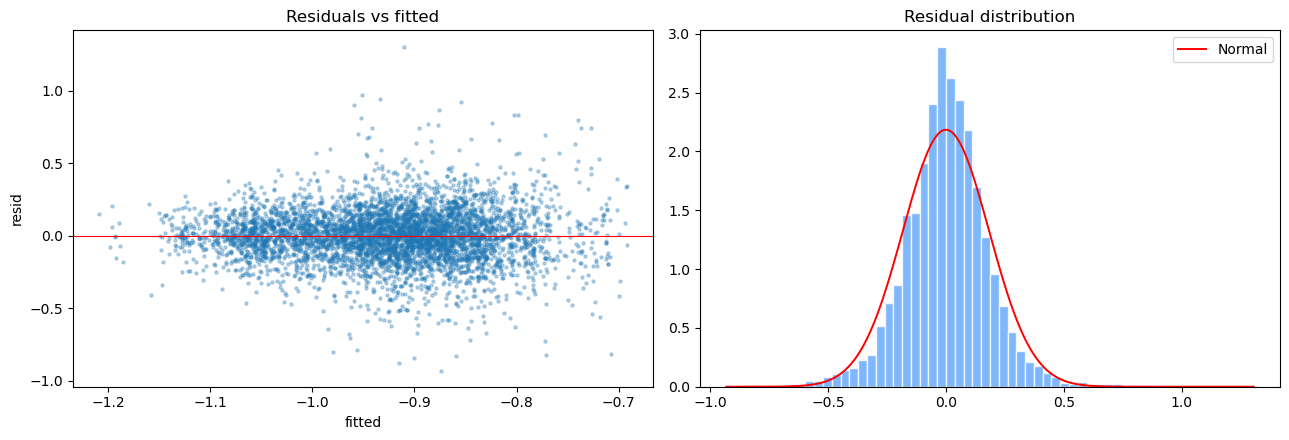

In [28]:
# ═════════════════════════════════════════════════════════════
# STEP 6 — Model evaluation & robustness
# ═════════════════════════════════════════════════════════════
sub = pdat[[OUTCOME]+X].dropna()
fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True,
              drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
resid = fe.resids.values.ravel(); fitted = fe.fitted_values.values.ravel()
jb_stat, jb_p = jarque_bera(resid)
_ex = sub[X].loc[fe.resids.index]
bp_lm, bp_p, _, _ = het_breuschpagan(resid, np.column_stack([np.ones(len(_ex)), _ex.values]))
dw = durbin_watson(resid)
print("RESIDUAL DIAGNOSTICS")
print(f"  Jarque-Bera (normality)   stat={jb_stat:.1f} p={jb_p:.4g} -> {'non-normal' if jb_p<0.05 else 'normal'}")
print(f"  Breusch-Pagan (heterosk.) LM={bp_lm:.1f} p={bp_p:.4g} -> {'heteroskedastic' if bp_p<0.05 else 'homoskedastic'}")
print(f"  Durbin-Watson             {dw:.3f} (2=none)")
print(f"  Skew={_st.skew(resid):.3f}  Excess kurtosis={_st.kurtosis(resid):.3f}")
print("  -> heavy tails expected in regency panels; handled by robust SE + large-n CLT.")
fig, ax = plt.subplots(1,2,figsize=(13,4.5))
ax[0].scatter(fitted,resid,s=5,alpha=.3); ax[0].axhline(0,color="red",lw=.8)
ax[0].set_title("Residuals vs fitted"); ax[0].set_xlabel("fitted"); ax[0].set_ylabel("resid")
ax[1].hist(resid,bins=60,density=True,color="#60a5fa",edgecolor="white",alpha=.8)
_xx=np.linspace(resid.min(),resid.max(),200); ax[1].plot(_xx,_st.norm.pdf(_xx,resid.mean(),resid.std()),"r-",lw=1.4,label="Normal")
ax[1].set_title("Residual distribution"); ax[1].legend(); plt.tight_layout(); plt.show()

In [30]:
# model fit summary (AIC/BIC/within-R2/F/RMSE) — reference; compare ACROSS files
def model_fit_summary(res, k):
    n=res.nobs
    return {"within_R2":res.rsquared_within,
            "adj_within_R2":1-(1-res.rsquared_within)*(n-1)/(n-k-1),
            "AIC":2*k-2*res.loglik,"BIC":k*np.log(n)-2*res.loglik,
            "logLik":res.loglik,"F":res.f_statistic.stat,"F_pval":res.f_statistic.pval,
            "RMSE":res.resids.std(),"n":int(n),"k_params":k}
sub = pdat[[OUTCOME]+X].dropna()
fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="kernel")
fs = model_fit_summary(fe, len(X))
print(f"MODEL FIT SUMMARY — {OUTCOME} ({len(FLOOD)}-var flood spec)\n")
for k,v in fs.items(): print(f"  {k:<16}{v:.4f}" if isinstance(v,float) else f"  {k:<16}{v}")
print("\n  AIC/BIC are RELATIVE - compare across the 3-dim vs 7-var file for this outcome.")
print("  Coefficient stability across control ladder:")
for nm,xv in [("flood only",FLOOD),("+pop",FLOOD+["log_population"]),("+rls (full)",FLOOD+CONTROLS)]:
    s2=pdat[[OUTCOME]+xv].dropna()
    r=PanelOLS(s2[OUTCOME],s2[xv],entity_effects=True,time_effects=True,drop_absorbed=True).fit(cov_type="kernel")
    print(f"    {nm:<16} beta({FLOOD[-1]})={r.params[FLOOD[-1]]:+.4f} p={r.pvalues[FLOOD[-1]]:.4f}")

MODEL FIT SUMMARY — tpt_pct (3-var flood spec)

  within_R2       0.0003
  adj_within_R2   -0.0007
  AIC             -2880.0925
  BIC             -2847.3685
  logLik          1445.0463
  F               2.5690
  F_pval          0.0250
  RMSE            0.1827
  n               5140
  k_params        5

  AIC/BIC are RELATIVE - compare across the 3-dim vs 7-var file for this outcome.
  Coefficient stability across control ladder:
    flood only       beta(PDI_log)=-0.0004 p=0.7332
    +pop             beta(PDI_log)=-0.0004 p=0.7207
    +rls (full)      beta(PDI_log)=-0.0004 p=0.7117


## STEP 7 — Export model fit (for cross-file comparison)

Writes fit metrics to `fit_10a.json`, read by the comparison notebook to build the side-by-side Excel (sheet per outcome).

In [32]:
# ═════════════════════════════════════════════════════════════
# STEP 7 — Export model fit
# ═════════════════════════════════════════════════════════════
import json
sub = pdat[[OUTCOME]+X].dropna()
_fe = PanelOLS(sub[OUTCOME], sub[X], entity_effects=True, time_effects=True, drop_absorbed=True).fit(cov_type="kernel")
_n=_fe.nobs; _k=len(X)
_fit = {"file":"10a","spec":"3dim","outcome":"tpt_pct","n_flood_predictors":len(FLOOD),
        "within_R2":float(_fe.rsquared_within),
        "adj_within_R2":float(1-(1-_fe.rsquared_within)*(_n-1)/(_n-_k-1)),
        "AIC":float(2*_k-2*_fe.loglik),"BIC":float(_k*np.log(_n)-2*_fe.loglik),
        "logLik":float(_fe.loglik),"F_stat":float(_fe.f_statistic.stat),
        "F_pval":float(_fe.f_statistic.pval),"RMSE":float(_fe.resids.std()),
        "n_obs":int(_n),"k_params":int(_k)}
with open("../data/processed/fit_10a.json","w") as _f: json.dump(_fit,_f,indent=2)
print(f"✓ saved fit_10a.json"); print(json.dumps(_fit, indent=2))

✓ saved fit_10a.json
{
  "file": "10a",
  "spec": "3dim",
  "outcome": "tpt_pct",
  "n_flood_predictors": 3,
  "within_R2": 0.0003193171300183151,
  "adj_within_R2": -0.0006542713807626832,
  "AIC": -2880.092540867215,
  "BIC": -2847.368499074969,
  "logLik": 1445.0462704336076,
  "F_stat": 2.5689832994612383,
  "F_pval": 0.02501268702571957,
  "RMSE": 0.18268742362482912,
  "n_obs": 5140,
  "k_params": 5
}
